Download the data from Moodle and place it in `data/` as shown below. Rename `T1w/` to `T1/`.

```text
NSSP-Mini-project-1/
  Project_notebook.ipynb
  data/
    T1/T1w.nii.gz
    fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR.nii.gz
    fMRI/tfMRI_LANGUAGE_LR/tfMRI_LANGUAGE_LR_task_onsets.csv
```

Requires FSL (`bet`, `fast`, `flirt`; `FSLDIR` set) and Python packages `nilearn`, `nibabel`, and `antspyx`.

In [2]:
import os
import os.path as op
import shutil
import subprocess
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from nilearn import plotting # brain image plotting

# Data folder, relative to this notebook: works on every machine without editing
data_dir = op.abspath("data")


out_dir = op.join(data_dir, "derivatives")
out_anatomical_dir = op.join(out_dir, "anat")
os.makedirs(out_dir, exist_ok=True)
os.makedirs(out_anatomical_dir, exist_ok=True)

t1_path = op.join(data_dir, "T1", "T1w.nii.gz") # original structural image
fig_dir = op.join(out_dir, "figures") # folder for the saved figures
os.makedirs(fig_dir, exist_ok=True)                 # create output folders (no error if they exist)
FIG_DPI = 300                                       # enough for the PDF report (1000 dpi gave 9000 px images)


# FSL environment
## REQUIRES FSL download (https://fsl.fmrib.ox.ac.uk/fsl/docs/install/index.html)
fsldir = os.environ.get("FSLDIR", op.expanduser("~/fsl"))  # FSL install folder (this is the default, change if needed)
os.environ["FSLDIR"] = fsldir                       # make sure FSL tools can find their files
os.environ["FSLOUTPUTTYPE"] = "NIFTI_GZ"            # FSL writes .nii.gz files
os.environ["PATH"] = os.pathsep.join([op.join(fsldir, "bin"), op.join(fsldir, "share", "fsl", "bin"), os.environ["PATH"]])

# MNI152 templates
mni_head = op.join(fsldir, "data", "standard", "MNI152_T1_2mm.nii.gz")        # whole-head template
mni_brain = op.join(fsldir, "data", "standard", "MNI152_T1_2mm_brain.nii.gz")  # skull-stripped template


assert op.exists(t1_path), f"T1w image not found: {t1_path}"
assert op.exists(out_anatomical_dir), f"Output directory not found: {out_anatomical_dir}"
assert op.exists(fig_dir), f"Output directory not found: {fig_dir}"
assert op.exists(mni_head), f"MNI template not found: {mni_head}"
assert op.exists(mni_brain), f"MNI template not found: {mni_brain}"
assert shutil.which("bet"), f"FSL tools not found in the PATH (FSLDIR={fsldir})"

print("All good. T1w:", t1_path)
print("FSL directory:", fsldir)

All good. T1w: /Users/matt/Desktop/NSSP-Mini-project-1/data/T1/T1w.nii.gz
FSL directory: /Users/matt/fsl


## 1. Skull stripping (BET)

BET removes non-brain tissue before segmentation and registration. We use robust centre estimation (`-R`) and `-f 0.3`; compare the `-f 0.5` result below and justify the chosen threshold in the report.

In [3]:
brain_prefix = op.join(out_anatomical_dir, "T1w_brain") # BET output name (without extension)
brain = brain_prefix + ".nii.gz"                        # skull-stripped brain image
mask = brain_prefix + "_mask.nii.gz"                    # binary brain mask

# FSL BET: -R robust centre estimation, -f 0.3 threshold (see justification above), -m save mask
subprocess.run(["bet", t1_path, brain_prefix, "-R", "-f", "0.3", "-m"], check=True)

CompletedProcess(args=['bet', '/Users/matt/Desktop/NSSP-Mini-project-1/data/T1/T1w.nii.gz', '/Users/matt/Desktop/NSSP-Mini-project-1/data/derivatives/anat/T1w_brain', '-R', '-f', '0.3', '-m'], returncode=0)

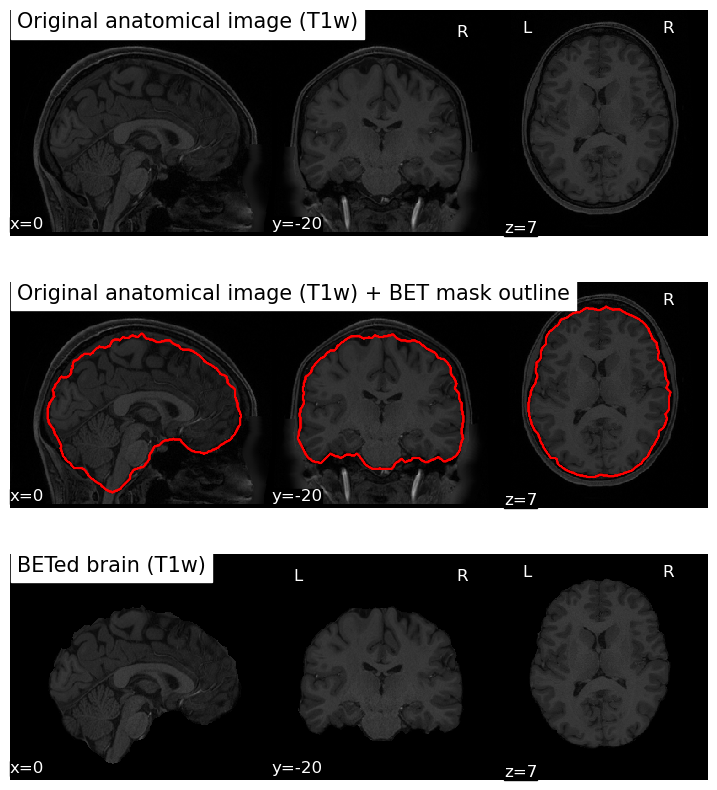

In [4]:
# Plotting results: same slices in every row, so that the rows can be compared
CUT = (0, -20, 7)
fig, axs = plt.subplots(3, 1, figsize=(9, 10))

# subplot 1: original T1w
plotting.plot_anat(t1_path, axes=axs[0], cut_coords=CUT, draw_cross=False,
                   title="Original anatomical image (T1w)", colorbar=False)

# subplot 2: original T1w with the brain mask outline in red (to check the extraction quality)
ax = plotting.plot_anat(t1_path, axes=axs[1], cut_coords=CUT, draw_cross=False,
                        title="Original anatomical image (T1w) + BET mask outline", colorbar=False)
ax.add_contours(mask, colors="r", linewidths=1)  # draw the mask boundary

# subplot 3: betted brain
plotting.plot_anat(brain, axes=axs[2], cut_coords=CUT, draw_cross=False,
                   title="BETed brain (T1w)", colorbar=False)

fig.savefig(op.join(fig_dir, "1_skull_stripping_BET.png"), dpi=FIG_DPI)
plt.show()

### BET threshold comparison

Compare `-f 0.3` and `-f 0.5` on the lower slices. The stricter mask removes some inferior tissue but avoids small non-brain islands; check that it does not cut the temporal poles or cerebellum.

Brain mask volume  -f 0.3: 1379 mL   -f 0.5: 1322 mL


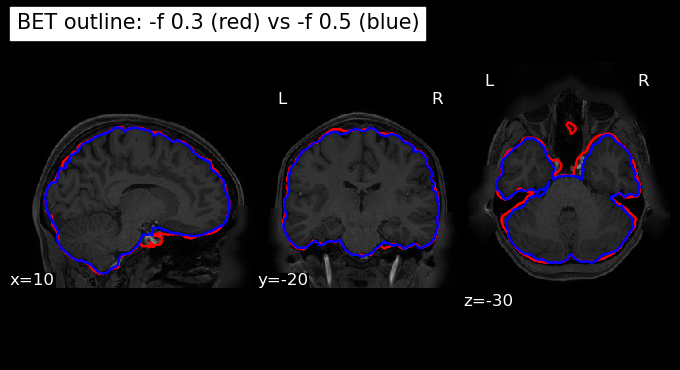

In [5]:
bet05_prefix = op.join(out_anatomical_dir, "T1w_brain_f05")
mask05 = bet05_prefix + "_mask.nii.gz"
subprocess.run(["bet", t1_path, bet05_prefix, "-R", "-f", "0.5", "-m"], check=True)

def volume_ml(img_path):
    """Volume (mL) of the non-zero voxels of an image."""
    img = nib.load(img_path)
    return (img.get_fdata() > 0).sum() * np.prod(img.header.get_zooms()[:3]) / 1000

print(f"Brain mask volume  -f 0.3: {volume_ml(mask):.0f} mL   -f 0.5: {volume_ml(mask05):.0f} mL")

d = plotting.plot_anat(t1_path, cut_coords=(10, -20, -30), draw_cross=False, colorbar=False,
                       title="BET outline: -f 0.3 (red) vs -f 0.5 (blue)")
d.add_contours(mask, colors="r", linewidths=1)
d.add_contours(mask05, colors="b", linewidths=1)
d.savefig(op.join(fig_dir, "annex_BET_threshold.png"), dpi=FIG_DPI)
plt.show()

## 2. Tissue segmentation (FAST)

FAST labels grey matter, white matter, and CSF. Inspect the segmentation and report the three tissue volumes; the masks are also used for nuisance regressors.

In [6]:
# Run FAST (takes a few minutes)
fast_prefix = op.join(out_anatomical_dir, "T1w_brain_fast")
seg = fast_prefix + "_seg.nii.gz"       # hard labels: 1 = CSF, 2 = GM, 3 = WM

# FAST: -t 1 = T1 image, -n 3 = three tissue classes
subprocess.run(["fast", "-t", "1", "-n", "3", "-o", fast_prefix, brain], check=True)

# Tissue volumes from the partial-volume maps (pve_k = fraction of tissue k in each voxel)
voxel_ml = np.prod(nib.load(brain).header.get_zooms()[:3]) / 1000
for k, name in enumerate(["CSF", "Grey matter", "White matter"]):
    pve = nib.load(f"{fast_prefix}_pve_{k}.nii.gz").get_fdata()
    print(f"{name:13s}: {pve.sum() * voxel_ml:4.0f} mL")

CSF          :  229 mL
Grey matter  :  654 mL
White matter :  496 mL


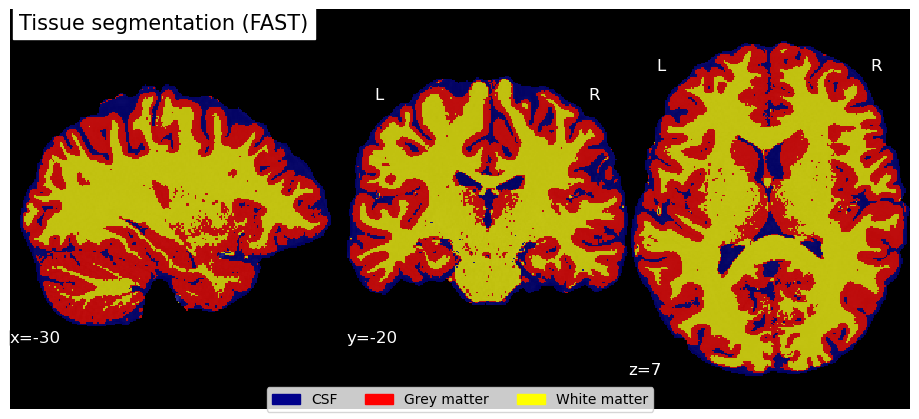

In [7]:
# Plotting the segmentation results
# x = -30: a lateral sagittal slice shows the cortical ribbon (x = 0 falls in the interhemispheric fissure)
fig = plt.figure(figsize=(9, 4))

plotting.plot_roi(seg, bg_img=brain, cut_coords=(-30, -20, 7), vmin=1, vmax=3,
                  cmap=ListedColormap(["darkblue", "red", "yellow"]),
                  alpha=0.7, colorbar=False, draw_cross=False, figure=fig,
                  title="Tissue segmentation (FAST)")



fig.legend(handles=[Patch(color="darkblue", label="CSF"),
                    Patch(color="red", label="Grey matter"),
                    Patch(color="yellow", label="White matter")],
           loc="lower center", ncol=3)

fig.savefig(op.join(fig_dir, "2_segmentation.png"), dpi=FIG_DPI)
plt.show()

## 3. Registration to MNI space

Register the anatomy to MNI so the results can be interpreted with standard coordinates and atlases. The registered anatomy also supports functional-to-anatomical alignment checks.

In [8]:
affine_mat = op.join(out_anatomical_dir, "T1_to_MNI_flirt.mat") # linear transformation matrix (from FLIRT)
brain_flirt = op.join(out_anatomical_dir, "T1w_brain_MNI_FLIRT.nii.gz")

# FLIRT: linear registration (defaults written explicitly: 12 DOF affine, correlation ratio cost)
subprocess.run(["flirt", "-in", brain, "-ref", mni_brain, "-out", brain_flirt, "-omat", affine_mat,
                "-dof", "12", "-cost", "corratio"], check=True)
print("FLIRT matrix:\n", np.loadtxt(affine_mat).round(3))


# ANTs SyN: non-linear registration (lab 2), initialised by an affine step inside ants.registration
import ants
brain_syn = op.join(out_anatomical_dir, "T1w_brain_MNI_SyN.nii.gz")
seg_mni = op.join(out_anatomical_dir, "T1w_brain_fast_seg_MNI_SyN.nii.gz")

mni_ants = ants.image_read(mni_brain)
tx = ants.registration(fixed=mni_ants, moving=ants.image_read(brain), type_of_transform="SyN")
ants.image_write(tx["warpedmovout"], brain_syn)

# same transform applied to the tissue labels (nearest neighbour keeps the labels 1/2/3)
seg_warped = ants.apply_transforms(fixed=mni_ants, moving=ants.image_read(seg),
                                   transformlist=tx["fwdtransforms"], interpolator="nearestNeighbor")
ants.image_write(seg_warped, seg_mni)


def match_with_mni(img_path):
    """Intensity correlation and Dice of the brain masks between an image and the MNI brain template."""
    x = nib.load(img_path).get_fdata()
    m = nib.load(mni_brain).get_fdata()
    union = (x > 0) | (m > 0)
    corr = np.corrcoef(x[union], m[union])[0, 1]
    dice = 2 * ((x > 0) & (m > 0)).sum() / ((x > 0).sum() + (m > 0).sum())
    return corr, dice

reg_scores = {name: match_with_mni(p) for name, p in [("FLIRT", brain_flirt), ("SyN", brain_syn)]}
for name, (corr, dice) in reg_scores.items():
    print(f"{name:5s}: correlation with MNI = {corr:.3f}   Dice = {dice:.3f}")

FLIRT matrix:
 [[ 1.0830e+00 -1.5000e-02  2.0000e-03 -6.2430e+00]
 [ 2.3000e-02  1.1230e+00 -6.0000e-03 -1.6255e+01]
 [-1.3000e-02 -5.0000e-03  1.1810e+00 -9.4730e+00]
 [ 0.0000e+00  0.0000e+00  0.0000e+00  1.0000e+00]]
FLIRT: correlation with MNI = 0.854   Dice = 0.894
SyN  : correlation with MNI = 0.809   Dice = 0.940


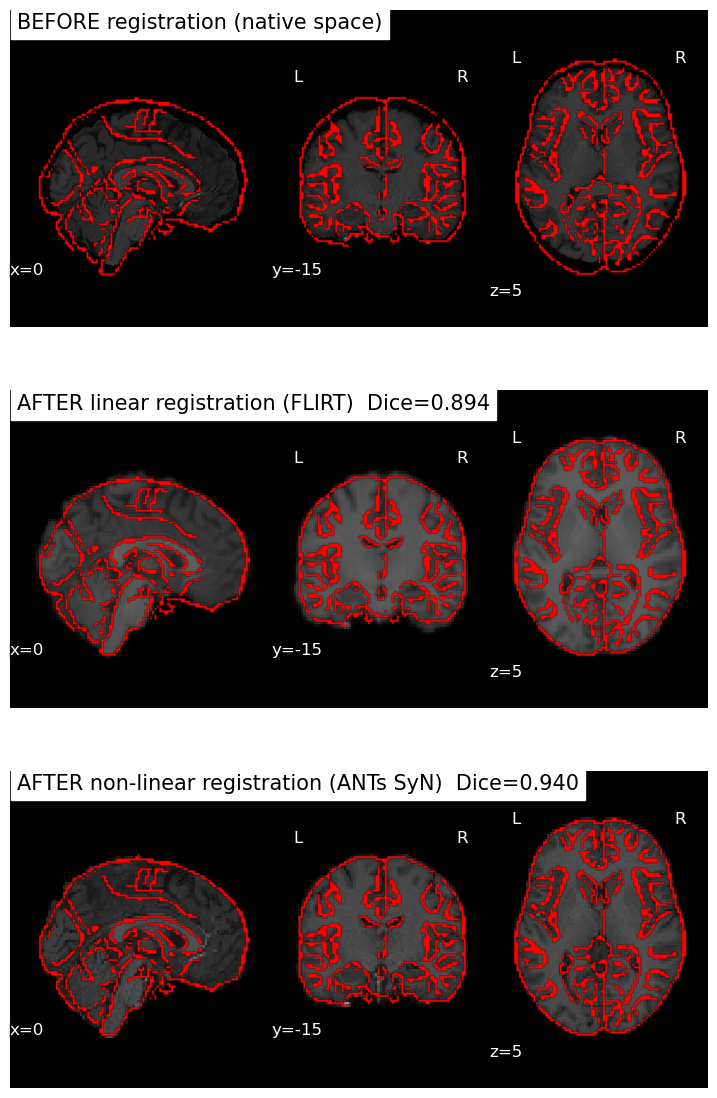

In [9]:
# Plotting pre- and post-registration results, same slices in every panel
CUT_MNI = (0, -15, 5)
fig, axs = plt.subplots(3, 1, figsize=(9, 14))

d = plotting.plot_anat(brain, axes=axs[0], cut_coords=CUT_MNI, draw_cross=False, colorbar=False,
                       title="BEFORE registration (native space)")
d.add_edges(mni_brain, color="r") # MNI edges on top

corr, dice = reg_scores["FLIRT"]
d = plotting.plot_anat(brain_flirt, axes=axs[1], cut_coords=CUT_MNI, draw_cross=False, colorbar=False,
                       title=f"AFTER linear registration (FLIRT)  Dice={dice:.3f}")
d.add_edges(mni_brain, color="r")

corr, dice = reg_scores["SyN"]
d = plotting.plot_anat(brain_syn, axes=axs[2], cut_coords=CUT_MNI, draw_cross=False, colorbar=False,
                       title=f"AFTER non-linear registration (ANTs SyN)  Dice={dice:.3f}")
d.add_edges(mni_brain, color="r")


fig.savefig(op.join(fig_dir, "3_registration_MNI.png"), dpi=FIG_DPI)
plt.show()

# Functional preprocessing (Part 1, practical 2)

The anatomy and fMRI run are ready for analysis. The next steps check the run, remove transient volumes, correct motion, smooth the data, and validate alignment.

## 4. Motion correction (MCFLIRT)

Inspect the global signal and remove transient initial volumes before realignment; shift the event onsets by the same duration. MCFLIRT estimates motion and framewise displacement (FD). Save the six motion parameters and one spike regressor per flagged volume for the GLM. Report the motion and FD results.

In [10]:
import pandas as pd
from nilearn import image

func_dir = op.join(data_dir, "fMRI", "tfMRI_LANGUAGE_LR")
func_path = op.join(func_dir, "tfMRI_LANGUAGE_LR.nii.gz")              # original fMRI run (4D)
events_path = op.join(func_dir, "tfMRI_LANGUAGE_LR_task_onsets.csv")   # task timing
out_func_dir = op.join(out_dir, "func")
os.makedirs(out_func_dir, exist_ok=True)
mni_brain_2mm = op.join(fsldir, "data", "standard", "MNI152_T1_2mm_brain.nii.gz")  # template at the fMRI resolution

assert op.exists(func_path), f"fMRI run not found: {func_path}"
assert op.exists(events_path), f"Onsets file not found: {events_path}"
assert shutil.which("mcflirt"), "FSL mcflirt not found in the PATH"

# Header check: voxel size, TR and grid are used by all the next steps
func_img = nib.load(func_path)
n_vols_raw = func_img.shape[3]
voxel_size = func_img.header.get_zooms()[:3]
TR = float(func_img.header.get_zooms()[3])                             # repetition time (s)
print(f"{n_vols_raw} volumes, voxel size {voxel_size} mm, TR = {TR} s, "
      f"on the MNI 2 mm grid: {np.allclose(func_img.affine, nib.load(mni_brain_2mm).affine)}")

events_raw = pd.read_csv(events_path)
last_event_end = (events_raw["onset"] + events_raw["duration"]).max()
print(f"Scan duration: {n_vols_raw * TR:.1f} s   last event ends at: {last_event_end:.1f} s")
if last_event_end > n_vols_raw * TR:
    print("-> the last events go past the end of the scan, they will be truncated in the GLM")

# Global signal: mean of the non-zero (brain) voxels of each volume (-t = one value per volume)
out = subprocess.run(["fslstats", "-t", func_path, "-M"], capture_output=True, text=True, check=True).stdout
global_raw = np.array(out.split(), dtype=float)
baseline = np.median(global_raw[10:])                                   # reference level, after the transient
print("First 10 volumes, % of baseline:", np.round(100 * (global_raw[:10] / baseline - 1), 2))

# Non-stationary volumes: chosen by looking at figure 4a (see the markdown, decided as a group)
N_DISCARD = 3

events = events_raw.copy()
if N_DISCARD > 0:
    func_input = op.join(out_func_dir, "func_trimmed.nii.gz")
    # fslroi: keep volumes N_DISCARD ... end (first volume is 0, not 1!)
    subprocess.run(["fslroi", func_path, func_input, str(N_DISCARD), str(n_vols_raw - N_DISCARD)], check=True)
    events["onset"] -= N_DISCARD * TR                                   # new time origin
    starts_before = events["onset"] < 0                                 # clip what starts before it
    events.loc[starts_before, "duration"] += events.loc[starts_before, "onset"]
    events.loc[starts_before, "onset"] = 0.0
    events = events[events["duration"] > 0].reset_index(drop=True)
else:
    func_input = func_path

n_vols = nib.load(func_input).shape[3]
events.to_csv(op.join(out_func_dir, "task_onsets_used.csv"), index=False)  # onsets to use in the GLM
print(f"Removed {N_DISCARD} volumes ({N_DISCARD * TR:.1f} s), kept {n_vols} volumes")

316 volumes, voxel size (np.float32(2.0), np.float32(2.0), np.float32(2.0)) mm, TR = 0.7200000286102295 s, on the MNI 2 mm grid: True
Scan duration: 227.5 s   last event ends at: 232.2 s
-> the last events go past the end of the scan, they will be truncated in the GLM
First 10 volumes, % of baseline: [0.98 0.49 0.24 0.07 0.13 0.19 0.16 0.23 0.33 0.36]
Removed 3 volumes (2.2 s), kept 313 volumes


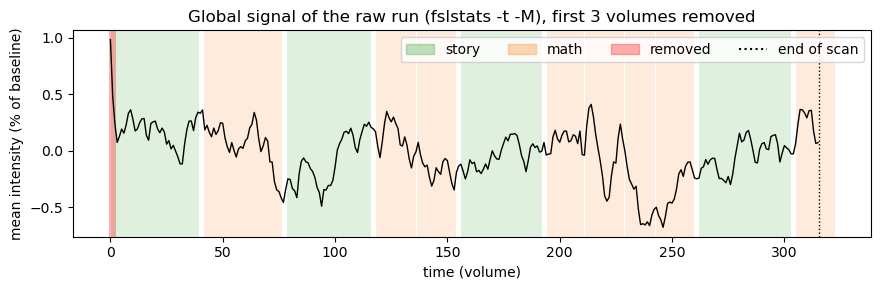

In [11]:
# Plotting the global signal of the raw run, with the task blocks and the removed volumes
block_colors = {"story": "tab:green", "math": "tab:orange"}
blocks_raw = events_raw[events_raw["trial_type"].isin(["story", "math"])]

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(np.arange(n_vols_raw), 100 * (global_raw / baseline - 1), color="k", lw=1)
for _, ev in blocks_raw.iterrows():                                     # task blocks, converted from s to volumes
    ax.axvspan(ev["onset"] / TR, (ev["onset"] + ev["duration"]) / TR,
               color=block_colors[ev["trial_type"]], alpha=0.15, lw=0)
if N_DISCARD > 0:
    ax.axvspan(-0.5, N_DISCARD - 0.5, color="r", alpha=0.3, lw=0)       # removed volumes
ax.axvline(n_vols_raw - 0.5, color="k", ls=":", lw=1)                   # end of the scan
ax.set(xlabel="time (volume)", ylabel="mean intensity (% of baseline)",
       title=f"Global signal of the raw run (fslstats -t -M), first {N_DISCARD} volumes removed")
ax.legend(handles=[Patch(color="tab:green", alpha=0.3, label="story"),
                   Patch(color="tab:orange", alpha=0.3, label="math"),
                   Patch(color="r", alpha=0.3, label="removed"),
                   plt.Line2D([], [], color="k", ls=":", label="end of scan")], loc="upper right", ncol=4)

fig.tight_layout()
fig.savefig(op.join(fig_dir, "4a_global_signal.png"), dpi=FIG_DPI)
plt.show()

In [12]:
mc_prefix = op.join(out_func_dir, "func_mc")
func_mc = mc_prefix + ".nii.gz"           # motion-corrected run
par_file = mc_prefix + ".par"             # 6 motion parameters per volume

# 3. MCFLIRT: rigid-body (6 DOF) realignment to the mean volume (takes a few minutes)
subprocess.run(["mcflirt", "-in", func_input, "-out", mc_prefix, "-dof", "6",
                "-meanvol", "-plots", "-rmsabs", "-rmsrel", "-spline_final"], check=True)
motion = np.loadtxt(par_file)             # columns: rx ry rz (rad), tx ty tz (mm)
assert motion.shape[0] == n_vols

# 4. Framewise displacement (Power et al., 2012)
HEAD_RADIUS = 50.0                        # mm, converts rotations (rad) into displacements (mm)
FD_THRESH = 0.5                           # mm, absolute threshold for the irregular volumes
delta = np.abs(np.diff(motion, axis=0))
fd = np.concatenate([[0.0], delta[:, 3:].sum(axis=1) + HEAD_RADIUS * delta[:, :3].sum(axis=1)])  # FD = 0 at the first volume
np.savetxt(op.join(out_func_dir, "fd.txt"), fd, fmt="%.5f")

q1, q3 = np.quantile(fd, [0.25, 0.75])
fd_boxplot = q3 + 1.5 * (q3 - q1)         # threshold of the lab, for comparison
outliers = np.where(fd > FD_THRESH)[0]
print(f"FD: mean = {fd.mean():.3f} mm, median = {np.median(fd):.3f} mm, max = {fd.max():.3f} mm")
print(f"Volumes with FD > {FD_THRESH} mm: {len(outliers)} / {n_vols}  {outliers.tolist()}")
print(f"(boxplot threshold Q3 + 1.5 IQR = {fd_boxplot:.3f} mm would flag {(fd > fd_boxplot).sum()} volumes)")

# 5. Irregular volumes: one spike regressor per flagged volume, saved with the 6 motion parameters for the GLM
spikes = np.zeros((n_vols, len(outliers)))
spikes[outliers, np.arange(len(outliers))] = 1
confounds = np.column_stack([motion, spikes])
np.savetxt(op.join(out_func_dir, "motion_confounds.txt"), confounds, fmt="%.6f")
print(f"Confound matrix: {confounds.shape}  (6 motion parameters + {len(outliers)} spike regressors)")

FD: mean = 0.094 mm, median = 0.076 mm, max = 0.391 mm
Volumes with FD > 0.5 mm: 0 / 313  []
(boxplot threshold Q3 + 1.5 IQR = 0.279 mm would flag 4 volumes)
Confound matrix: (313, 6)  (6 motion parameters + 0 spike regressors)


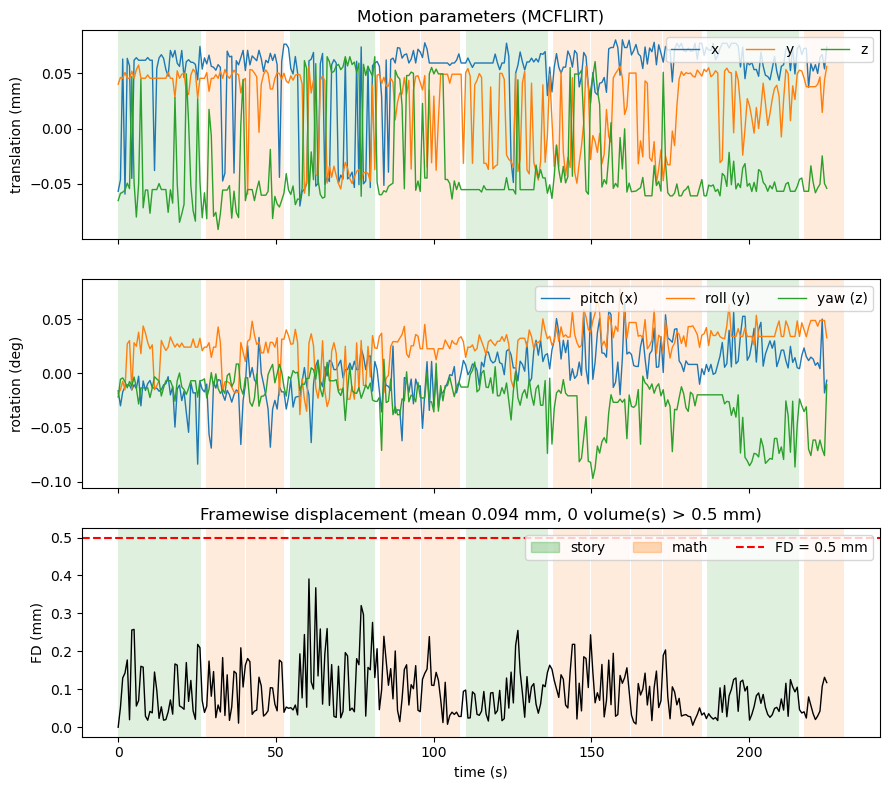

In [13]:
# Plotting the motion parameters and the FD, with the task blocks in the background
t = np.arange(n_vols) * TR
blocks = events[events["trial_type"].isin(["story", "math"])]           # onsets after the possible shift

fig, axs = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
axs[0].plot(t, motion[:, 3:], lw=1)
axs[0].set(ylabel="translation (mm)", title="Motion parameters (MCFLIRT)")
axs[0].legend(["x", "y", "z"], loc="upper right", ncol=3)
axs[1].plot(t, np.degrees(motion[:, :3]), lw=1)
axs[1].set(ylabel="rotation (deg)")
axs[1].legend(["pitch (x)", "roll (y)", "yaw (z)"], loc="upper right", ncol=3)
axs[2].plot(t, fd, color="k", lw=1)
axs[2].axhline(FD_THRESH, color="r", ls="--")
axs[2].scatter(t[outliers], fd[outliers], color="r", zorder=3)
axs[2].set(ylabel="FD (mm)", xlabel="time (s)",
           title=f"Framewise displacement (mean {fd.mean():.3f} mm, {len(outliers)} volume(s) > {FD_THRESH} mm)")

for ax in axs:                                                          # shade the story/math blocks
    for _, ev in blocks.iterrows():
        ax.axvspan(ev["onset"], ev["onset"] + ev["duration"], color=block_colors[ev["trial_type"]], alpha=0.15, lw=0)
axs[2].legend(handles=[Patch(color="tab:green", alpha=0.3, label="story"),
                       Patch(color="tab:orange", alpha=0.3, label="math"),
                       plt.Line2D([], [], color="r", ls="--", label=f"FD = {FD_THRESH} mm")],
              loc="upper right", ncol=3)

fig.tight_layout()
fig.savefig(op.join(fig_dir, "4b_motion_FD.png"), dpi=FIG_DPI)
plt.show()

Mean DVARS  before MC: 4.822 %   after MC: 4.839 %


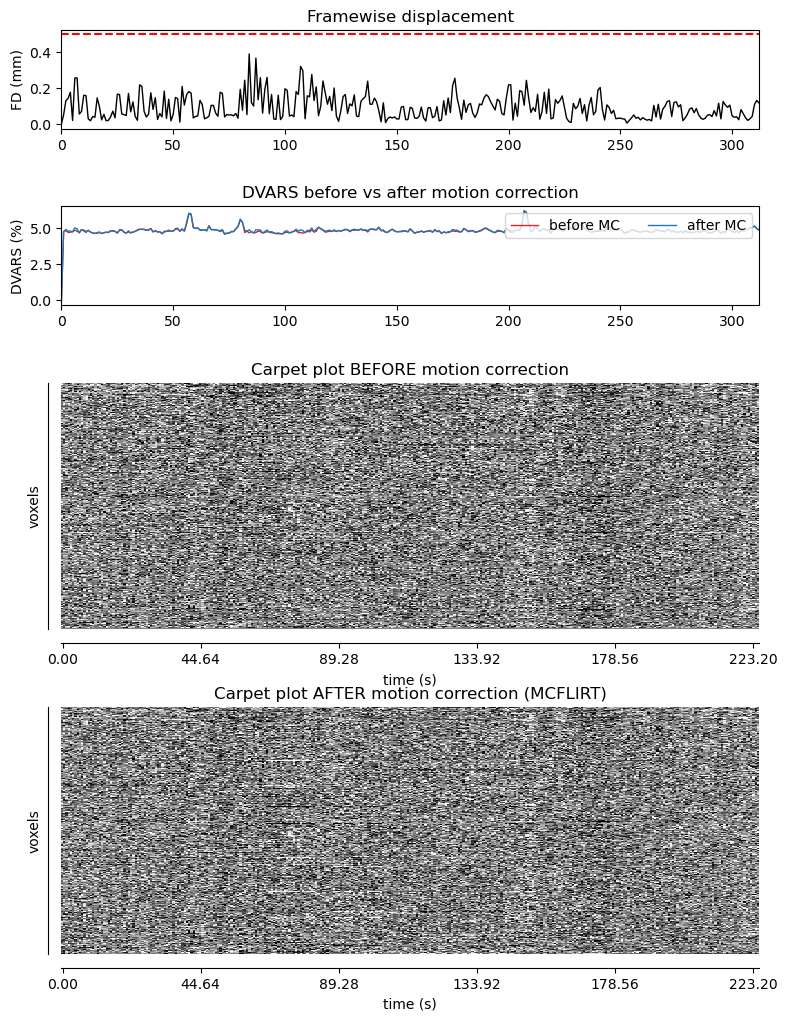

In [14]:
# Effect of motion correction: DVARS and carpet plots before vs after MCFLIRT, aligned with the FD
mni_mask_2mm = op.join(fsldir, "data", "standard", "MNI152_T1_2mm_brain_mask.nii.gz")  # same grid as the fMRI
brain_vox = nib.load(mni_mask_2mm).get_fdata() > 0

def dvars_pct(img_path):
    """DVARS (Power et al., 2012): RMS over voxels of the volume-to-volume signal change, in % of the mean signal."""
    data = nib.load(img_path).get_fdata(dtype=np.float32)[brain_vox]   # voxels x time
    dv = np.sqrt(np.mean(np.diff(data, axis=1) ** 2, axis=0)) / data.mean() * 100
    return np.concatenate([[0.0], dv])                                  # DVARS = 0 at the first volume

dvars_before, dvars_after = dvars_pct(func_input), dvars_pct(func_mc)
print(f"Mean DVARS  before MC: {dvars_before.mean():.3f} %   after MC: {dvars_after.mean():.3f} %")

fig = plt.figure(figsize=(9, 12))
gs = fig.add_gridspec(4, 1, height_ratios=[1, 1, 2.5, 2.5], hspace=0.45)

ax = fig.add_subplot(gs[0])
ax.plot(np.arange(n_vols), fd, color="k", lw=1)
ax.axhline(FD_THRESH, color="r", ls="--")
ax.set(ylabel="FD (mm)", xlim=(0, n_vols - 1), title="Framewise displacement")

ax = fig.add_subplot(gs[1])
ax.plot(np.arange(n_vols), dvars_before, color="tab:red", lw=1, label="before MC")
ax.plot(np.arange(n_vols), dvars_after, color="tab:blue", lw=1, label="after MC")
ax.set(ylabel="DVARS (%)", xlim=(0, n_vols - 1), title="DVARS before vs after motion correction")
ax.legend(loc="upper right", ncol=2)

# Carpet plot: one row per brain voxel (detrended, z-scored), one column per volume.
# Motion would appear as vertical stripes across many voxels at the same time.
plotting.plot_carpet(func_input, mask_img=mni_mask_2mm, axes=fig.add_subplot(gs[2]),
                     title="Carpet plot BEFORE motion correction")
plotting.plot_carpet(func_mc, mask_img=mni_mask_2mm, axes=fig.add_subplot(gs[3]),
                     title="Carpet plot AFTER motion correction (MCFLIRT)")

fig.savefig(op.join(fig_dir, "4c_motion_correction_effect.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 5. Gaussian smoothing

Smooth the masked run with a 6 mm FWHM Gaussian. Compare a volume before and after smoothing and report the effect on temporal SNR; note the loss of spatial detail.

In [15]:
# Functional brain mask: BET on the temporal mean of the motion-corrected run
mean_func = op.join(out_func_dir, "func_mc_mean.nii.gz")          # temporal mean (3D)
func_brain_prefix = op.join(out_func_dir, "func_mean_brain")
func_mask = func_brain_prefix + "_mask.nii.gz"                     # functional brain mask
func_mc_brain = op.join(out_func_dir, "func_mc_brain.nii.gz")      # masked motion-corrected run

subprocess.run(["fslmaths", func_mc, "-Tmean", mean_func], check=True)
subprocess.run(["bet", mean_func, func_brain_prefix, "-f", "0.3", "-m"], check=True)
subprocess.run(["fslmaths", func_mc, "-mas", func_mask, func_mc_brain], check=True)
print(f"Functional mask volume: {volume_ml(func_mask):.0f} mL   (T1 BET mask: {volume_ml(mask):.0f} mL)")

# Gaussian smoothing inside the mask: smooth(data) / smooth(mask), then re-mask
FWHM = 6.0                                                         # mm (decided as a group)
sigma = FWHM / (2 * np.sqrt(2 * np.log(2)))                        # FSL uses sigma, not FWHM
func_smooth = op.join(out_func_dir, f"func_mc_brain_smooth{FWHM:.0f}mm.nii.gz")
tmp_num = op.join(out_func_dir, "tmp_smooth_data.nii.gz")
tmp_den = op.join(out_func_dir, "tmp_smooth_mask.nii.gz")

subprocess.run(["fslmaths", func_mc_brain, "-s", f"{sigma:.4f}", tmp_num], check=True)
subprocess.run(["fslmaths", func_mask, "-s", f"{sigma:.4f}", tmp_den], check=True)
subprocess.run(["fslmaths", tmp_num, "-div", tmp_den, "-mas", func_mask, func_smooth, "-odt", "float"], check=True)
os.remove(tmp_num); os.remove(tmp_den)
print(f"FWHM = {FWHM} mm  ->  sigma = {sigma:.3f} mm")

def median_tsnr(img_4d, mask_path):
    """Median temporal SNR (mean / std over time) in the mask, computed with fslmaths."""
    m, s, r = (op.join(out_func_dir, f"tmp_{k}.nii.gz") for k in ("mean", "std", "tsnr"))
    subprocess.run(["fslmaths", img_4d, "-Tmean", m], check=True)
    subprocess.run(["fslmaths", img_4d, "-Tstd", s], check=True)
    subprocess.run(["fslmaths", m, "-div", s, "-mas", mask_path, r], check=True)
    vals = nib.load(r).get_fdata()[nib.load(mask_path).get_fdata() > 0]
    for f in (m, s, r): os.remove(f)
    return np.median(vals)

tsnr_before, tsnr_after = median_tsnr(func_mc_brain, func_mask), median_tsnr(func_smooth, func_mask)
print(f"Median tSNR  before smoothing: {tsnr_before:.1f}   after: {tsnr_after:.1f}")

Functional mask volume: 1874 mL   (T1 BET mask: 1379 mL)
FWHM = 6.0 mm  ->  sigma = 2.548 mm
Median tSNR  before smoothing: 32.6   after: 127.4


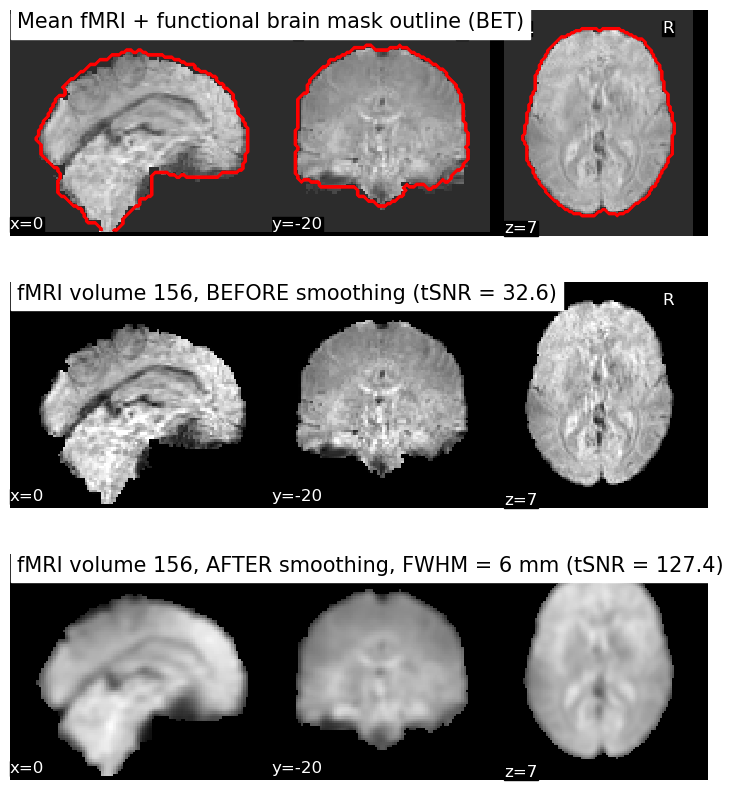

In [16]:
# Plotting the functional mask, then one volume before and after smoothing (same slices, same intensity scale)
VOL = n_vols // 2                                    # volume of our choice: the middle of the run
vol_before = op.join(out_func_dir, f"vol{VOL}_before_smoothing.nii.gz")
vol_after = op.join(out_func_dir, f"vol{VOL}_after_smoothing.nii.gz")
subprocess.run(["fslroi", func_mc_brain, vol_before, str(VOL), "1"], check=True)   # extract 1 volume
subprocess.run(["fslroi", func_smooth, vol_after, str(VOL), "1"], check=True)

data_before = nib.load(vol_before).get_fdata()
vmax = np.percentile(data_before[data_before > 0], 99)  # common scale for both volumes

CUT_FUNC = (0, -20, 7)
fig, axs = plt.subplots(3, 1, figsize=(9, 10))

d = plotting.plot_epi(mean_func, axes=axs[0], cut_coords=CUT_FUNC, draw_cross=False, colorbar=False, cmap="gray",
                      title="Mean fMRI + functional brain mask outline (BET)")
d.add_contours(func_mask, colors="r", linewidths=1)

plotting.plot_epi(vol_before, axes=axs[1], cut_coords=CUT_FUNC, draw_cross=False, colorbar=False,
                  cmap="gray", vmin=0, vmax=vmax, title=f"fMRI volume {VOL}, BEFORE smoothing (tSNR = {tsnr_before:.1f})")

plotting.plot_epi(vol_after, axes=axs[2], cut_coords=CUT_FUNC, draw_cross=False, colorbar=False,
                  cmap="gray", vmin=0, vmax=vmax,
                  title=f"fMRI volume {VOL}, AFTER smoothing, FWHM = {FWHM:.0f} mm (tSNR = {tsnr_after:.1f})")

fig.savefig(op.join(fig_dir, "5_smoothing.png"), dpi=FIG_DPI)
plt.show()

## 6. Anatomical-functional alignment

Check the fMRI-to-anatomical overlay in MNI space. Report whether the brain boundaries and internal landmarks align, and whether the preprocessing needs improvement.

Dice (functional vs T1 brain mask): 0.950
Residual misalignment found by FLIRT (RMS displacement): 1.02 mm  (voxel size 2 mm)


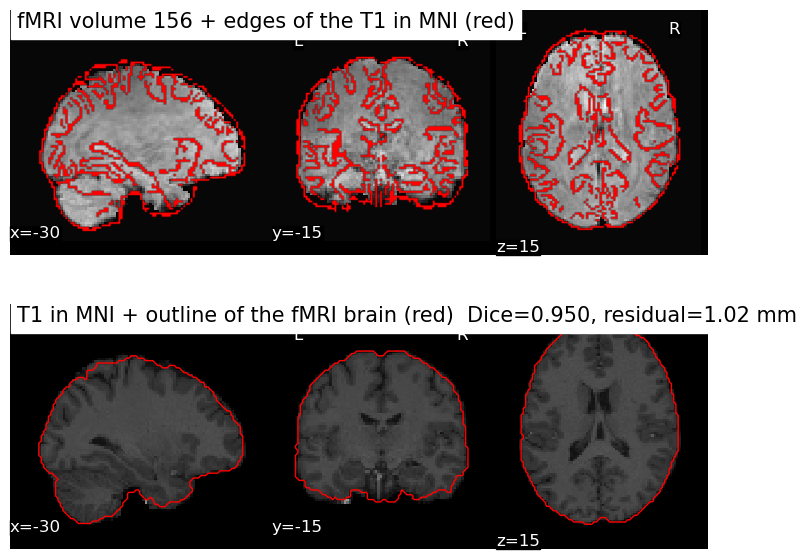

In [17]:
# Dice between the functional mask (resampled to 1 mm) and the T1 brain mask in MNI (outer boundary only)
func_mask_1mm = image.resample_to_img(func_mask, brain_syn, interpolation="nearest").get_fdata() > 0
t1_mask_mni = nib.load(brain_syn).get_fdata() > 0
dice_func_t1 = 2 * (func_mask_1mm & t1_mask_mni).sum() / (func_mask_1mm.sum() + t1_mask_mni.sum())

# Residual misalignment: rigid FLIRT of the mean fMRI onto the T1 in MNI, starting from the current position.
# If the data are aligned, FLIRT finds (almost) the identity: the RMS displacement it would apply is ~0 mm.
resid_mat = op.join(out_func_dir, "func_to_T1MNI_residual.mat")
ident_mat = op.join(out_func_dir, "identity.mat")
np.savetxt(ident_mat, np.eye(4), fmt="%.1f")
subprocess.run(["flirt", "-in", mean_func, "-ref", brain_syn, "-omat", resid_mat,
                "-dof", "6", "-cost", "normmi", "-nosearch"], check=True)   # normmi: different contrasts (EPI vs T1)
rms_resid = float(subprocess.run(["rmsdiff", ident_mat, resid_mat, brain_syn],
                                 capture_output=True, text=True, check=True).stdout.split()[0])
print(f"Dice (functional vs T1 brain mask): {dice_func_t1:.3f}")
print(f"Residual misalignment found by FLIRT (RMS displacement): {rms_resid:.2f} mm  (voxel size {voxel_size[0]:.0f} mm)")

# Plotting: T1 edges over the fMRI, and the fMRI brain outline over the T1
CUT_ALIGN = (-30, -15, 15)                           # lateral slices through the ventricles and the insula
fig, axs = plt.subplots(2, 1, figsize=(9, 7))

d = plotting.plot_epi(vol_before, axes=axs[0], cut_coords=CUT_ALIGN, draw_cross=False, colorbar=False, cmap="gray",
                      title=f"fMRI volume {VOL} + edges of the T1 in MNI (red)")
d.add_edges(brain_syn, color="r")

d = plotting.plot_anat(brain_syn, axes=axs[1], cut_coords=CUT_ALIGN, draw_cross=False, colorbar=False,
                       title=f"T1 in MNI + outline of the fMRI brain (red)  Dice={dice_func_t1:.3f}, "
                             f"residual={rms_resid:.2f} mm")
d.add_contours(func_mask, levels=[0.5], colors="r", linewidths=1)

fig.savefig(op.join(fig_dir, "6_func_anat_alignment.png"), dpi=FIG_DPI)
plt.show()

# Part 1: GLM

Use the preprocessed single-subject language run to compare story and math blocks. The sections below cover the GLM practical tasks (3a–3f).

## 3a. Design matrix

Model the alternating story and math blocks with a canonical SPM HRF, cosine drifts, an intercept, and the six motion parameters (plus any spike regressors).

313 volumes; TR = 0.720 s
Block design columns: ['math', 'story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']
Event design columns: ['cue', 'present_math', 'present_story', 'question_math', 'question_story', 'response_math', 'response_story', 'rot_x', 'rot_y', 'rot_z', 'trans_x', 'trans_y', 'trans_z', 'drift_1', 'drift_2', 'drift_3', 'drift_4', 'constant']


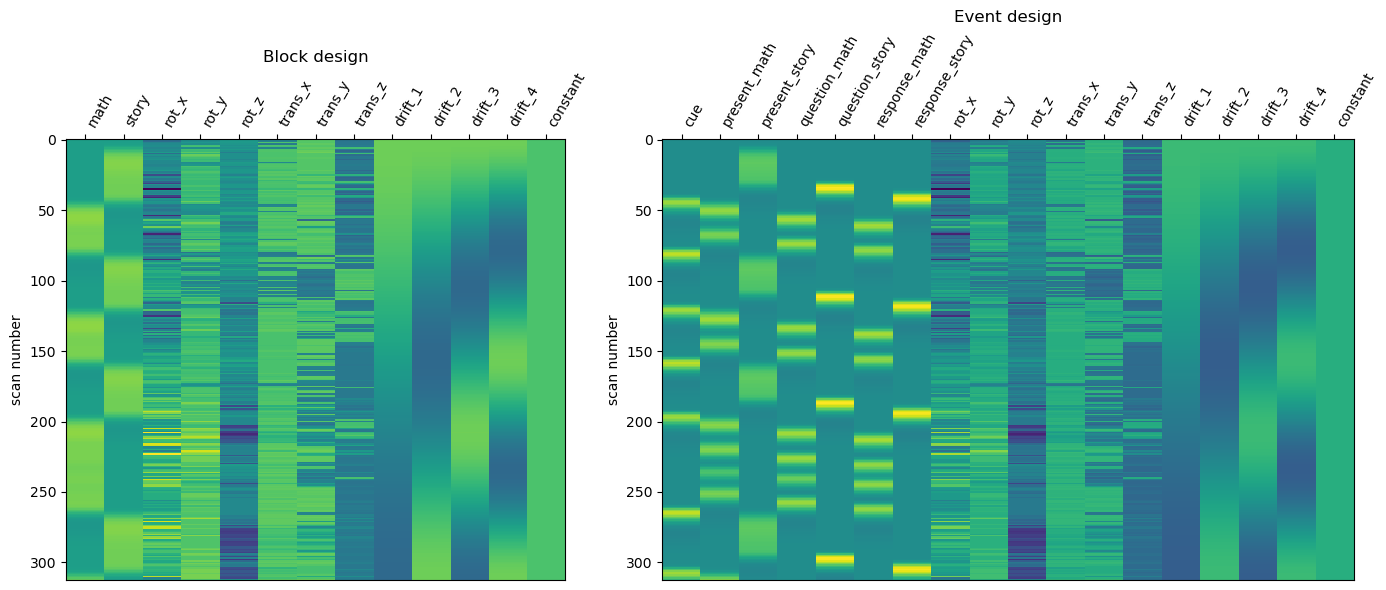

In [38]:
from nilearn.glm.first_level import make_first_level_design_matrix
from nilearn.plotting import plot_design_matrix

func_dir = out_func_dir
glm_dir = op.join(out_dir, "glm")
os.makedirs(glm_dir, exist_ok=True)
func_img_path = op.join(func_dir, "func_mc_brain_smooth6mm.nii.gz")
events_path = op.join(func_dir, "task_onsets_used.csv")
confounds_path = op.join(func_dir, "motion_confounds.txt")
func_mask = op.join(func_dir, "func_mean_brain_mask.nii.gz")
anat_mni = op.join(out_anatomical_dir, "T1w_brain_MNI_SyN.nii.gz")
for required in (func_img_path, events_path, confounds_path, func_mask, anat_mni):
    assert op.exists(required), f"Missing {required}; run the preprocessing sections first"

func_header = nib.load(func_img_path).header
n_scans = func_header.get_data_shape()[3]
t_r = float(func_header.get_zooms()[3])
frame_times = np.arange(n_scans) * t_r
events = pd.read_csv(events_path)

BLOCK_CONDITIONS = ["story", "math"]
EVENT_CONDITIONS = ["present_story", "question_story", "response_story",
                    "present_math", "question_math", "response_math", "cue"]
motion = np.loadtxt(confounds_path, ndmin=2)
assert motion.shape[0] == n_scans, "Motion confounds and fMRI run have different lengths"
motion_names = ["rot_x", "rot_y", "rot_z", "trans_x", "trans_y", "trans_z"]
motion_names += [f"spike_{i}" for i in range(motion.shape[1] - len(motion_names))]


def build_design(conditions):
    selected_events = events[events["trial_type"].isin(conditions)]
    return make_first_level_design_matrix(
        frame_times,
        selected_events,
        hrf_model="spm",
        drift_model="cosine",
        high_pass=0.01,
        add_regs=motion,
        add_reg_names=motion_names,
    )


dm_block = build_design(BLOCK_CONDITIONS)
dm_event = build_design(EVENT_CONDITIONS)
dm_block.to_csv(op.join(glm_dir, "design_matrix_block.csv"))
dm_event.to_csv(op.join(glm_dir, "design_matrix_event.csv"))
print(f"{n_scans} volumes; TR = {t_r:.3f} s")
print("Block design columns:", list(dm_block.columns))
print("Event design columns:", list(dm_event.columns))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [dm_block.shape[1], dm_event.shape[1]]})
plot_design_matrix(dm_block, axes=axes[0])
axes[0].set_title("Block design")
plot_design_matrix(dm_event, axes=axes[1])
axes[1].set_title("Event design")
fig.tight_layout()
fig.savefig(op.join(out_dir, "figures", "7a_design_matrix.png"), dpi=FIG_DPI)
plt.show()

## 3b. Regressor correlations

Plot the Pearson correlations between design regressors. The constant is omitted because it has zero variance.

/var/folders/lh/h2h4w7096rl5sh2stqh35lb00000gn/T/ipykernel_25278/3526872204.py:10: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


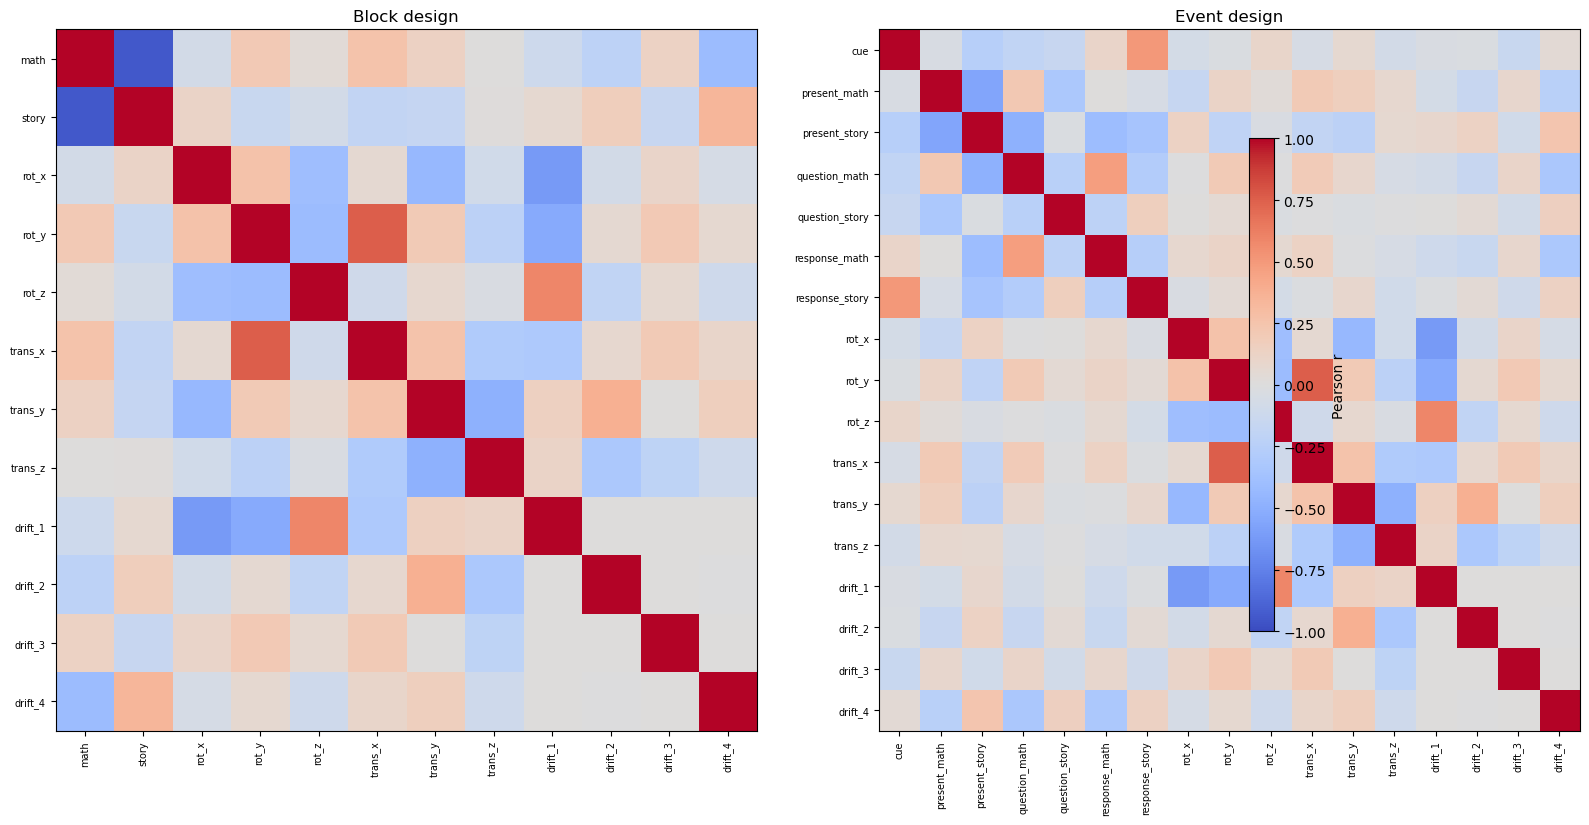

Block task-regressor correlation:
       story   math
story  1.000 -0.943
math  -0.943  1.000
Event task-regressor correlation:
                present_story  question_story  response_story  present_math  \
present_story           1.000          -0.028          -0.347        -0.562   
question_story         -0.028           1.000           0.160        -0.313   
response_story         -0.347           0.160           1.000        -0.050   
present_math           -0.562          -0.313          -0.050         1.000   
question_math          -0.486          -0.238          -0.281         0.216   
response_math          -0.400          -0.214          -0.264         0.004   
cue                    -0.256          -0.153           0.504        -0.040   

                question_math  response_math    cue  
present_story          -0.486         -0.400 -0.256  
question_story         -0.238         -0.214 -0.153  
response_story         -0.281         -0.264  0.504  
present_math           

In [39]:
corr_block = dm_block.drop(columns="constant").corr()
corr_event = dm_event.drop(columns="constant").corr()
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
for ax, corr, title in zip(axes, (corr_block, corr_event), ("Block design", "Event design")):
    image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr.index)), corr.index, fontsize=7)
    ax.set_title(title)
fig.colorbar(image, ax=axes, label="Pearson r", shrink=0.8)
fig.tight_layout()
fig.savefig(op.join(out_dir, "figures", "7b_regressor_correlation.png"), dpi=FIG_DPI)
plt.show()
print("Block task-regressor correlation:")
print(corr_block.loc[BLOCK_CONDITIONS, BLOCK_CONDITIONS].round(3))
print("Event task-regressor correlation:")
print(corr_event.loc[EVENT_CONDITIONS, EVENT_CONDITIONS].round(3))

## 3c. GLM and task-regressor maps

Fit a first-level AR(1) model and report thresholded z-maps for story and math, each compared with the implicit baseline.

/var/folders/lh/h2h4w7096rl5sh2stqh35lb00000gn/T/ipykernel_25278/473560200.py:21: UserWarning: If design matrices are supplied, [t_r] will be ignored.
  return model.fit(func_img_path, design_matrices=design)
/var/folders/lh/h2h4w7096rl5sh2stqh35lb00000gn/T/ipykernel_25278/473560200.py:21: RuntimeWarning: [MultiNiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  return model.fit(func_img_path, design_matrices=design)


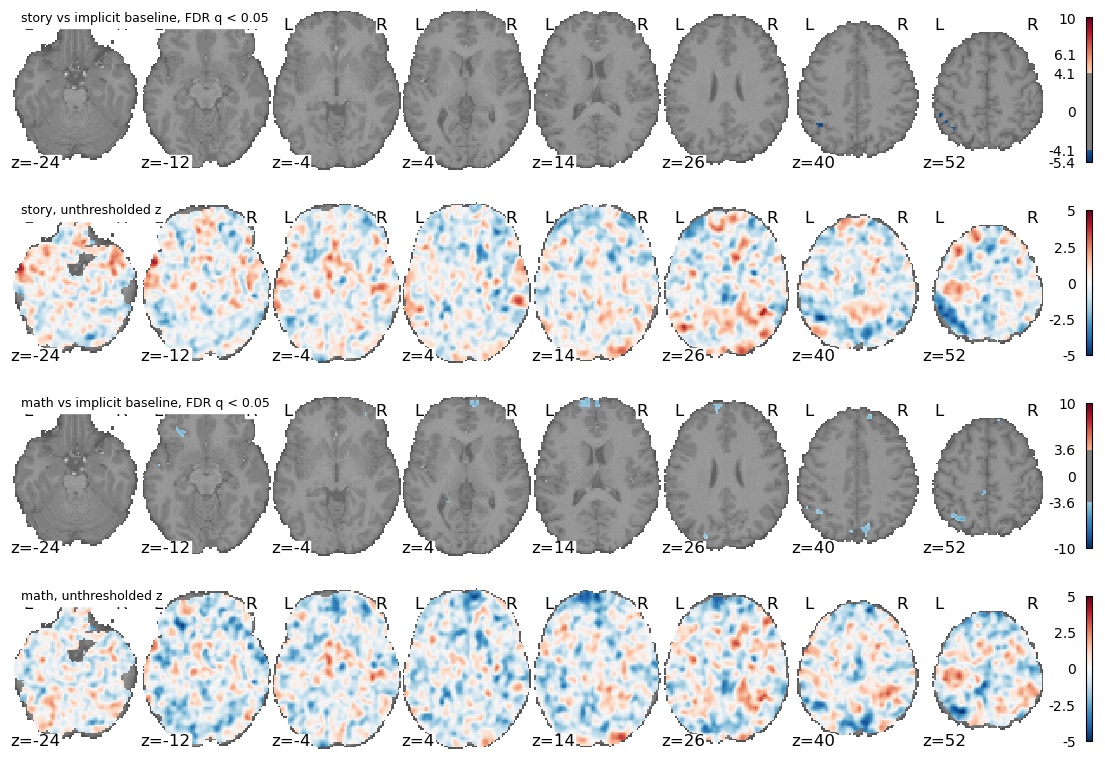

/var/folders/lh/h2h4w7096rl5sh2stqh35lb00000gn/T/ipykernel_25278/473560200.py:43: UserWarning: empty mask
  display = plotting.plot_stat_map(


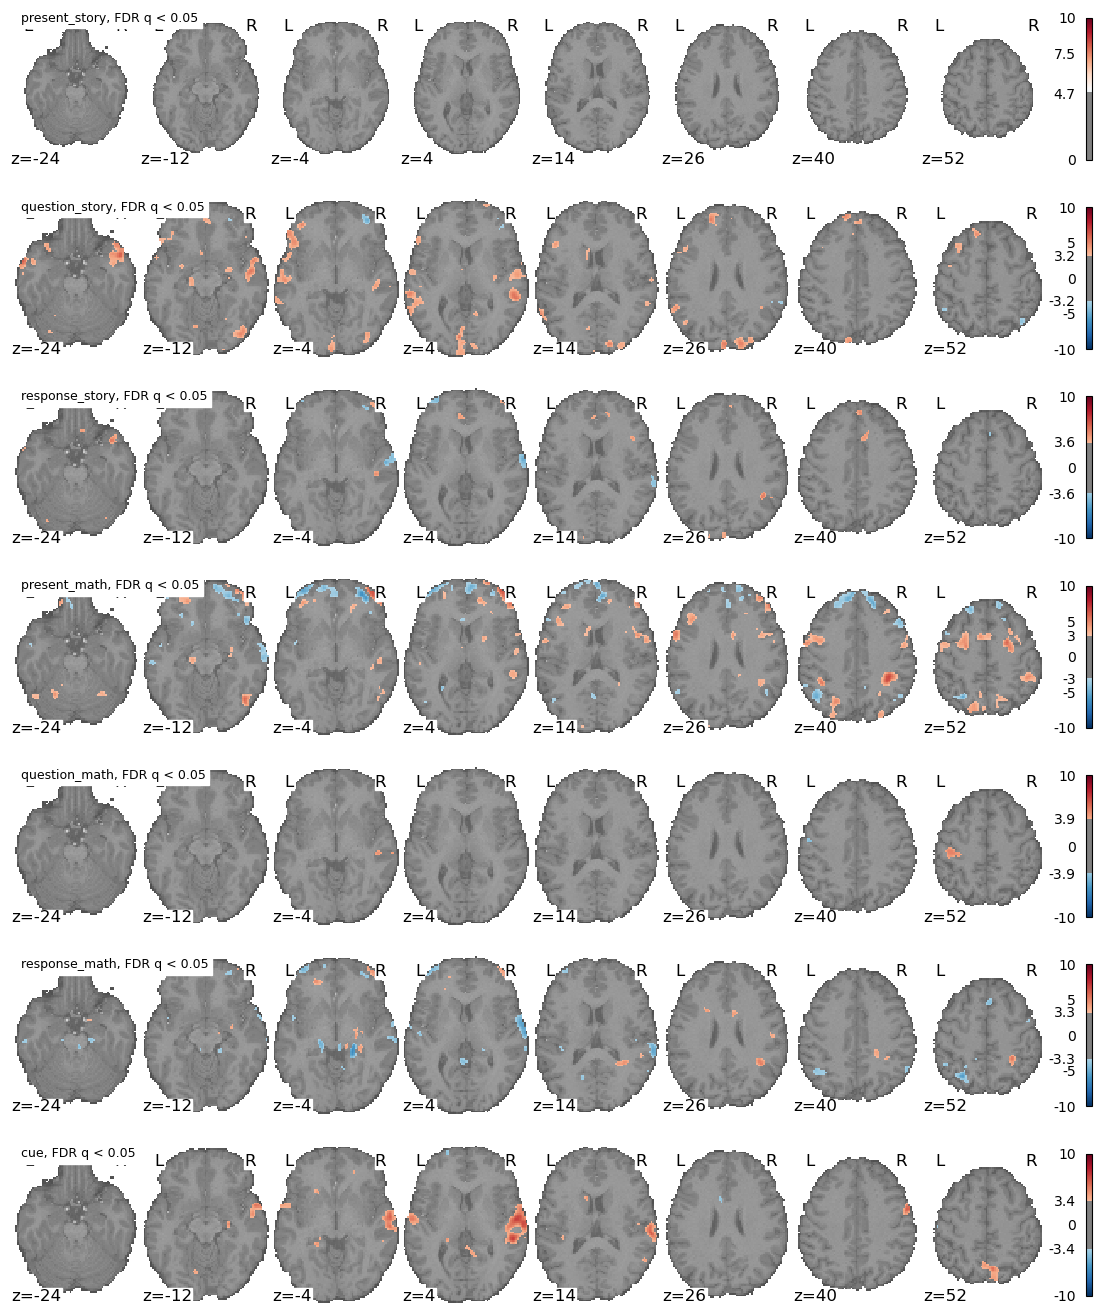

In [40]:
from nilearn.glm.first_level import FirstLevelModel
from nilearn.glm import threshold_stats_img
from nilearn.reporting import get_clusters_table
from nilearn import plotting

FDR_ALPHA = 0.05
CLUSTER_SIZE = 10
Z_CUTS = [-24, -12, -4, 4, 14, 26, 40, 52]
Z_VMAX = 10


def fit_glm(design):
    model = FirstLevelModel(
        t_r=t_r,
        mask_img=func_mask,
        smoothing_fwhm=None,
        noise_model="ar1",
        signal_scaling=0,
        minimize_memory=True,
    )
    return model.fit(func_img_path, design_matrices=design)


def contrast_vector(design, weights):
    vector = np.zeros(design.shape[1])
    for column, weight in weights.items():
        vector[design.columns.get_loc(column)] = weight
    return vector


def threshold(z_map, control="fdr", alpha=FDR_ALPHA):
    return threshold_stats_img(
        z_map,
        mask_img=func_mask,
        alpha=alpha,
        height_control=control,
        cluster_threshold=CLUSTER_SIZE,
        two_sided=True,
    )


def plot_map(z_map, z_threshold, title, axes, vmax=Z_VMAX):
    display = plotting.plot_stat_map(
        z_map,
        bg_img=anat_mni,
        display_mode="z",
        cut_coords=Z_CUTS,
        axes=axes,
        threshold=z_threshold,
        vmax=vmax,
        cmap="RdBu_r",
        black_bg=False,
        annotate=True,
        draw_cross=False,
    )
    display.title(title, size=9, color="black", bgcolor="white")
    return display


glm_block = fit_glm(dm_block)
glm_event = fit_glm(dm_event)

z_maps = {}
summary = []
for model_name, model, design, conditions in (
    ("block", glm_block, dm_block, BLOCK_CONDITIONS),
    ("event", glm_event, dm_event, EVENT_CONDITIONS),
):
    for condition in conditions:
        z_map = model.compute_contrast(contrast_vector(design, {condition: 1}), output_type="z_score")
        z_map.to_filename(op.join(glm_dir, f"zmap_{model_name}_{condition}.nii.gz"))
        z_maps[(model_name, condition)] = z_map
        thresholded, z_threshold = threshold(z_map)
        z_data = z_map.get_fdata()
        thresholded_data = thresholded.get_fdata()
        summary.append({
            "model": model_name,
            "regressor": condition,
            "z threshold": round(z_threshold, 2),
            "voxels z>0": int((thresholded_data > 0).sum()),
            "voxels z<0": int((thresholded_data < 0).sum()),
            "max z": round(float(z_data.max()), 1),
            "min z": round(float(z_data.min()), 1),
        })

pd.DataFrame(summary).to_csv(op.join(glm_dir, "regressor_maps_summary.csv"), index=False)

fig, axes = plt.subplots(2 * len(BLOCK_CONDITIONS), 1, figsize=(14, 9.6))
for index, condition in enumerate(BLOCK_CONDITIONS):
    thresholded, z_threshold = threshold(z_maps[("block", condition)])
    plot_map(thresholded, z_threshold,
             f"{condition} vs implicit baseline, FDR q < {FDR_ALPHA}", axes[2 * index])
    plot_map(z_maps[("block", condition)], 0, f"{condition}, unthresholded z", axes[2 * index + 1], vmax=5)
fig.savefig(op.join(out_dir, "figures", "7c_regressor_maps_block.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(len(EVENT_CONDITIONS), 1, figsize=(14, 2.4 * len(EVENT_CONDITIONS)))
for ax, condition in zip(axes, EVENT_CONDITIONS):
    thresholded, z_threshold = threshold(z_maps[("event", condition)])
    plot_map(thresholded, z_threshold, f"{condition}, FDR q < {FDR_ALPHA}", ax)
fig.savefig(op.join(out_dir, "figures", "annex_regressor_maps_event.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 3d. Story–math contrast

Contrast story against math. Positive values indicate greater activity during story; negative values indicate greater activity during math. Report the contrast vector and map.

Contrast vector story - math:
math       -1
story       1
rot_x       0
rot_y       0
rot_z       0
trans_x     0
trans_y     0
trans_z     0
drift_1     0
drift_2     0
drift_3     0
drift_4     0
constant    0

FDR threshold |z| > 2.42:  story > math 47034 voxels,  math > story 24703 voxels
Cluster ID     X     Y     Z  Peak Stat Cluster Size (mm3)
         1  -4.0  60.0  28.0  10.815451             340208
        1a -20.0  40.0  50.0  10.439586                   
        1b -54.0  -4.0 -10.0  10.193111                   
        1c   0.0  56.0  -8.0  10.172563                   
         2  24.0 -82.0 -44.0   8.373362               8264
        2a  32.0 -70.0 -38.0   6.400430                   
        2b  34.0 -82.0 -34.0   5.733446                   
        2c  18.0 -66.0 -32.0   5.271110                   
         3 -38.0 -72.0 -36.0   6.681596               3440
        3a -32.0 -80.0 -32.0   6.018302                   
        3b -22.0 -84.0 -38.0   3.526422                  

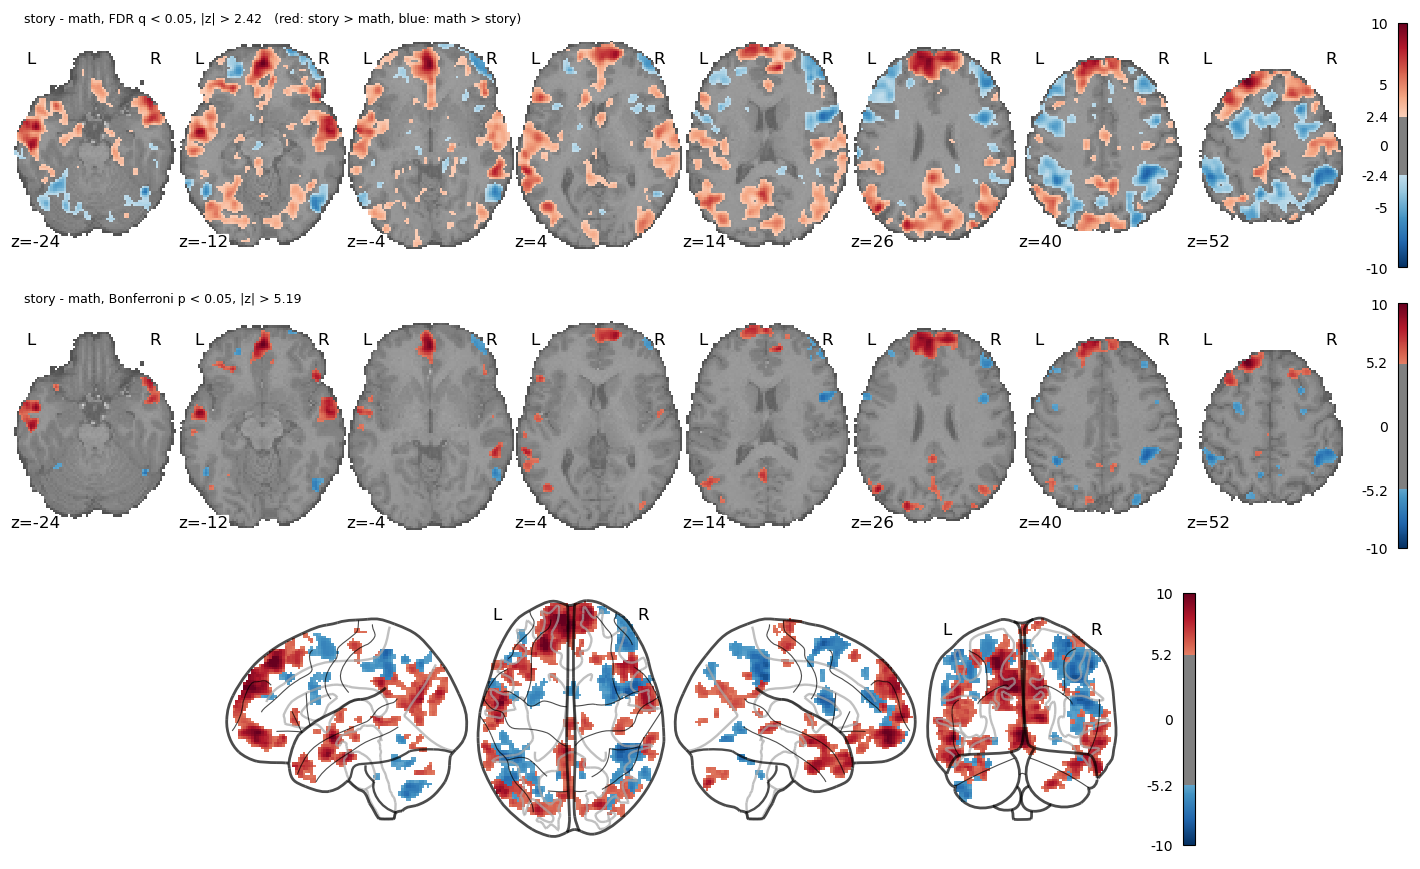

In [41]:
c_story_math = contrast_vector(dm_block, {"story": 1, "math": -1})
print("Contrast vector story - math:")
print(pd.Series(c_story_math, index=dm_block.columns).astype(int).to_string())

z_sm = glm_block.compute_contrast(c_story_math, output_type="z_score")
z_sm.to_filename(op.join(glm_dir, "zmap_story_minus_math.nii.gz"))
z_sm_thr, thr_sm = threshold(z_sm)
z_sm_thr.to_filename(op.join(glm_dir, "zmap_story_minus_math_thr.nii.gz"))
d = z_sm_thr.get_fdata()
print(f"\nFDR threshold |z| > {thr_sm:.2f}:  story > math {(d > 0).sum()} voxels,  math > story {(d < 0).sum()} voxels")

clusters = get_clusters_table(z_sm, stat_threshold=thr_sm, cluster_threshold=CLUSTER_SIZE, two_sided=True)
clusters.to_csv(op.join(glm_dir, "clusters_story_minus_math.csv"), index=False)
print(clusters.head(25).to_string(index=False))

# %%
# Stricter control for the figure: Bonferroni (family-wise error) at 0.05, which keeps only the core regions
z_sm_bonf, thr_bonf = threshold(z_sm, control="bonferroni", alpha=0.05)
d = z_sm_bonf.get_fdata()
print(f"Bonferroni threshold |z| > {thr_bonf:.2f}:  story > math {(d > 0).sum()} voxels,  math > story {(d < 0).sum()} voxels")

# Figure: story - math contrast, FDR and Bonferroni, axial slices + glass brain (Bonferroni)
fig = plt.figure(figsize=(14, 8.5))
ax_fdr = fig.add_axes([0, 0.68, 1, 0.32])
ax_bonf = fig.add_axes([0, 0.35, 1, 0.32])
ax_glass = fig.add_axes([0.15, 0, 0.7, 0.33])
plot_map(z_sm_thr, thr_sm, f"story - math, FDR q < {FDR_ALPHA}, |z| > {thr_sm:.2f}   (red: story > math, blue: math > story)", ax_fdr)
plot_map(z_sm_bonf, thr_bonf, f"story - math, Bonferroni p < 0.05, |z| > {thr_bonf:.2f}", ax_bonf)
plotting.plot_glass_brain(z_sm_bonf, threshold=thr_bonf, vmax=Z_VMAX, cmap="RdBu_r", plot_abs=False,
                          colorbar=True, display_mode="lzry", axes=ax_glass)
fig.savefig(op.join(fig_dir, "7d_contrast_story_minus_math.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

## 3e. Brain regions and functional networks

Overlay the contrast on the seven Yeo networks and summarize which networks contain story-greater or math-greater significant voxels.

In [35]:
import urllib.request
from nilearn import datasets, image

atlas_dir = op.join(out_dir, "atlases")
os.makedirs(atlas_dir, exist_ok=True)
YEO_URL = ("https://raw.githubusercontent.com/ThomasYeoLab/CBIG/master/stable_projects/brain_parcellation/"
           "Yeo2011_fcMRI_clustering/1000subjects_reference/Yeo_JNeurophysiol11_SplitLabels/MNI152/")
YEO_FILE = "Yeo2011_7Networks_N1000.split_components.FSL_MNI152_2mm.nii.gz"
YEO_LUT = "7Networks_ColorLUT_freeview.txt"
for f in (YEO_FILE, YEO_LUT):
    if not op.exists(op.join(atlas_dir, f)):
        urllib.request.urlretrieve(YEO_URL + f, op.join(atlas_dir, f))

# The split atlas has 51 components (e.g. "7Networks_LH_Default_Temp"): grouped into the 7 networks
NETWORKS = {"Vis": "Visual", "SomMot": "Somatomotor", "DorsAttn": "Dorsal attention",
            "SalVentAttn": "Ventral attention / salience", "Limbic": "Limbic", "Cont": "Frontoparietal control",
            "Default": "Default mode"}
NETWORK_COLORS = {"Visual": "#781286", "Somatomotor": "#4682b4", "Dorsal attention": "#00760e",
                  "Ventral attention / salience": "#c43afa", "Limbic": "#b8c96a",     # Yeo's colours (limbic darkened)
                  "Frontoparietal control": "#e69422", "Default mode": "#cd3e4e"}
lut = pd.read_csv(op.join(atlas_dir, YEO_LUT), sep=r"\s+", header=None, usecols=[0, 1], names=["index", "name"])
lut = lut[lut["index"] > 0]
lut["network"] = lut["name"].str.split("_").str[2].map(NETWORKS)

yeo_img = nib.load(op.join(atlas_dir, YEO_FILE))
z_img = nib.load(op.join(glm_dir, "zmap_story_minus_math.nii.gz"))
assert np.allclose(yeo_img.affine, z_img.affine) and yeo_img.shape[:3] == z_img.shape[:3], "atlas not on the fMRI grid"
yeo_split = np.squeeze(yeo_img.get_fdata()).astype(int)
from scipy import ndimage

mask_data = nib.load(func_mask).get_fdata() > 0
YEO_DILATION = 2                                                        # voxels (4 mm)
dist, (ii, jj, kk) = ndimage.distance_transform_edt(yeo_split == 0, return_indices=True)
yeo_split = np.where(mask_data & (dist <= YEO_DILATION), yeo_split[ii, jj, kk], yeo_split)
yeo_net = np.full(yeo_split.shape, "", dtype=object)                    # network name of each voxel
for _, row in lut.iterrows():
    yeo_net[yeo_split == row["index"]] = row["network"]
z_data = z_img.get_fdata()
z_fdr = z_sm_thr.get_fdata()
story_vox, math_vox = (z_fdr > 0) & mask_data, (z_fdr < 0) & mask_data

rows = []
for net in NETWORK_COLORS:
    in_net = (yeo_net == net) & mask_data
    rows.append({"network": net, "voxels": int(in_net.sum()),
                 "coverage story>math (%)": 100 * (story_vox & in_net).sum() / in_net.sum(),
                 "coverage math>story (%)": 100 * (math_vox & in_net).sum() / in_net.sum(),
                 "mean z": z_data[in_net].mean(),
                 "composition story>math (%)": 100 * (story_vox & in_net).sum() / story_vox.sum(),
                 "composition math>story (%)": 100 * (math_vox & in_net).sum() / math_vox.sum()})
outside = (yeo_net == "") & mask_data
rows.append({"network": "outside Yeo (subcortex, cerebellum, WM)", "voxels": int(outside.sum()),
             "coverage story>math (%)": 100 * (story_vox & outside).sum() / outside.sum(),
             "coverage math>story (%)": 100 * (math_vox & outside).sum() / outside.sum(),
             "mean z": z_data[outside].mean(),
             "composition story>math (%)": 100 * (story_vox & outside).sum() / story_vox.sum(),
             "composition math>story (%)": 100 * (math_vox & outside).sum() / math_vox.sum()})
network_table = pd.DataFrame(rows).round(1)
network_table.to_csv(op.join(glm_dir, "networks_story_minus_math.csv"), index=False)
print(network_table.to_string(index=False))

network_display = plotting.plot_roi(
    yeo_img, bg_img=anat_mni, display_mode="z", cut_coords=Z_CUTS,
    black_bg=False, draw_cross=False,
)
network_display.savefig(op.join(out_dir, "figures", "7e_network_atlas.png"))
network_display.close()

                                network  voxels  coverage story>math (%)  coverage math>story (%)  mean z  composition story>math (%)  composition math>story (%)
                                 Visual   30292                     28.6                      3.2     1.3                        18.4                         3.9
                            Somatomotor   25890                     32.6                      2.4     1.5                        18.0                         2.5
                       Dorsal attention   18437                      7.2                     33.0    -1.3                         2.8                        24.6
           Ventral attention / salience   17951                      9.9                     14.3    -0.2                         3.8                        10.4
                                 Limbic   13727                     27.1                      1.3     1.4                         7.9                         0.7
                 Frontoparie

## 3f. Semantic-language regions (hard question)

Check whether story-greater activity overlaps literature-based semantic regions. If expected regions are absent, discuss at least two possible causes, such as single-subject variability, limited signal-to-noise, thresholding, or atlas alignment.

In [ ]:
from nilearn.image import resample_to_img

BINDER_ROIS = {                                       # Harvard-Oxford cortical label -> short name
    "Temporal Pole": "temporal pole",
    "Superior Temporal Gyrus, anterior division": "ant. STG",
    "Middle Temporal Gyrus, anterior division": "ant. MTG",
    "Inferior Temporal Gyrus, anterior division": "ant. ITG (ventral ATL)",
    "Temporal Fusiform Cortex, anterior division": "ant. fusiform (ventral ATL)",
    "Parahippocampal Gyrus, anterior division": "ant. parahippocampal (ventral ATL)",
    "Middle Temporal Gyrus, posterior division": "post. MTG",
    "Angular Gyrus": "angular gyrus",
    "Inferior Frontal Gyrus, pars triangularis": "IFG triangularis",
    "Frontal Orbital Cortex": "orbitofrontal / IFG orbitalis",
    "Superior Frontal Gyrus": "dorsomedial PFC (SFG)",
    "Frontal Medial Cortex": "ventromedial PFC",
    "Cingulate Gyrus, posterior division": "posterior cingulate",
}

# Temporal SNR of the motion-corrected run before smoothing (part 1-2)
func_mc_brain = op.join(func_dir, "func_mc_brain.nii.gz")
mc_data = nib.load(func_mc_brain).get_fdata(dtype=np.float32)
mc_mean, mc_std = mc_data.mean(axis=3), mc_data.std(axis=3)
tsnr = np.divide(mc_mean, mc_std, out=np.zeros_like(mc_mean), where=mc_std > 0)
del mc_data
mni_brain_mask = datasets.load_mni152_brain_mask(resolution=2)            # whole-brain reference (MNI)
mni_brain_resampled = resample_to_img(
    mni_brain_mask, z_img, interpolation="nearest"
)
mni_brain = np.squeeze(mni_brain_resampled.get_fdata()) > 0
tsnr_brain = np.median(tsnr[mask_data])

x_mm = z_img.affine[0, 0] * np.arange(z_img.shape[0]) + z_img.affine[0, 3]   # MNI x of each voxel column
left = np.broadcast_to(x_mm[:, None, None] < 0, z_img.shape[:3])

rows = []
for ho_label, short in BINDER_ROIS.items():
    if "ho_cort_data" not in globals() or "ho_cort" not in globals():
        ho_cort = datasets.fetch_atlas_harvard_oxford("cort-maxprob-thr25-2mm")
        ho_cort_img = image.load_img(ho_cort.maps)
        ho_cort_resampled = resample_to_img(
            ho_cort_img, z_img, interpolation="nearest"
        )
        ho_cort_data = np.rint(ho_cort_resampled.get_fdata()).astype(int)

    if ho_label not in ho_cort.labels:
        raise ValueError(f"ROI label not found in Harvard–Oxford atlas: {ho_label}")

    roi_all = ho_cort_data == ho_cort.labels.index(ho_label)
    for side, hemi in (("L", left), ("R", ~left)):
        roi = roi_all & hemi & mni_brain
        roi_in = roi & mask_data
        rows.append({"region": short, "side": side,
                     "in func. mask (%)": 100 * roi_in.sum() / roi.sum(),
                     "median tSNR": np.median(tsnr[roi_in]) if roi_in.any() else 0,
                     "story>math (%)": 100 * (story_vox & roi).sum() / roi.sum(),
                     "math>story (%)": 100 * (math_vox & roi).sum() / roi.sum(),
                     "peak z": z_data[roi_in].max() if roi_in.any() else np.nan})
binder_table = pd.DataFrame(rows).round(1)
binder_table.to_csv(op.join(glm_dir, "binder_regions_story_minus_math.csv"), index=False)
print(f"Median tSNR of the brain: {tsnr_brain:.1f}")
print(binder_table.to_string(index=False))

# %%
# Figure: coronal slices through the ATL (contrast and tSNR), and the expected regions
Y_CUTS = [20, 10, 0, -10, -20, -40, -60]                                 # temporal pole -> angular gyrus
tsnr_img = nib.Nifti1Image(np.where(mask_data, tsnr, 0), z_img.affine)

fig = plt.figure(figsize=(14, 12))
ax_c = fig.add_axes([0, 0.78, 1, 0.21])
ax_t = fig.add_axes([0, 0.56, 1, 0.21])
ax_r = fig.add_axes([0.22, 0.03, 0.36, 0.48])
ax_s = fig.add_axes([0.62, 0.03, 0.2, 0.48])
display = plotting.plot_stat_map(z_sm_thr, bg_img=anat_mni, display_mode="y", cut_coords=Y_CUTS, axes=ax_c,
                                 threshold=thr_sm, vmax=Z_VMAX, cmap="RdBu_r", black_bg=False, draw_cross=False)
display.title(f"story - math, FDR q < {FDR_ALPHA}, coronal slices from the temporal pole (y = 20) to the angular gyrus",
              size=9, color="black", bgcolor="white")
display = plotting.plot_stat_map(tsnr_img, bg_img=anat_mni, display_mode="y", cut_coords=Y_CUTS, axes=ax_t,
                                 cmap="viridis", vmin=0, vmax=60, threshold=0.1, symmetric_cbar=False,
                                 black_bg=False, draw_cross=False)
display.title("temporal SNR of the motion-corrected run (before smoothing)", size=9, color="black", bgcolor="white")

regions = list(BINDER_ROIS.values())[::-1]
ypos = np.arange(len(regions))
bt = binder_table.set_index(["region", "side"])
L_COLOR, R_COLOR = "#b3302f", "#e8a39c"                                  # left darker: the expected dominant side
for side, color, dy in (("L", L_COLOR, 0.18), ("R", R_COLOR, -0.18)):
    ax_r.barh(ypos + dy, [bt.loc[(r, side), "story>math (%)"] for r in regions], height=0.36, color=color,
              label=f"{side} hemisphere")
    ax_s.scatter([bt.loc[(r, side), "median tSNR"] for r in regions], ypos + dy, color=color, s=40, zorder=3)
ax_r.set_yticks(ypos, regions, fontsize=9)
ax_r.set_xlim(0, 100)
ax_r.set_xlabel("% of the region's voxels with story > math (FDR)")
ax_r.legend(loc="lower right", frameon=False, fontsize=8)
ax_s.axvline(tsnr_brain, color="#333333", ls="--", lw=1)
ax_s.text(tsnr_brain + 1, len(regions) - 0.4, "brain\nmedian", fontsize=8, color="#333333", va="top")
ax_s.set_yticks(ypos, [])
ax_s.set_xlim(0, 60)
ax_s.set_xlabel("median tSNR")
for ax in (ax_r, ax_s):
    ax.set_ylim(-0.6, len(regions) - 0.4)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color="0.9")
    ax.set_axisbelow(True)
ax_r.set_title("Semantic regions expected from Binder et al. (2009, 2011)", fontsize=10, loc="left")
fig.savefig(op.join(fig_dir, "7f_semantic_regions.png"), dpi=FIG_DPI, bbox_inches="tight")
plt.show()

NameError: name 'ho_cort_data' is not defined